In [1]:
!pip -q install -U transformers datasets accelerate scikit-learn gradio matplotlib pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
ydata-profiling 4.18.4 requires pandas!=1.4.0,<3.0,>1.5, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires 

In [2]:
import re, random, json
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from collections import Counter
from datasets import load_dataset, Dataset, DatasetDict, concatenate_datasets
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding,
                          EarlyStoppingCallback, pipeline)
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    _, _, f1w, _ = precision_recall_fscore_support(labels, preds, average="weighted", zero_division=0)
    return {"accuracy": accuracy_score(labels, preds), "precision_macro": p,
            "recall_macro": r, "f1_macro": f1, "f1_weighted": f1w}

class WeightedTrainer(Trainer):
    """Trainer with optional class weights (used for imbalanced data)."""
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        w = self.class_weights.to(outputs.logits.device) if self.class_weights is not None else None
        loss = torch.nn.functional.cross_entropy(outputs.logits, labels, weight=w)
        return (loss, outputs) if return_outputs else loss

def dedup(d, text_col="text"):
    df = d.to_pandas().drop_duplicates(subset=text_col).reset_index(drop=True)
    return Dataset.from_pandas(df, features=d.features, preserve_index=False)

def train_model(model_name, run_name, splits, id2label, lr=5e-5, epochs=5,
                batch_size=32, max_length=64, class_weights=None):
    """splits: DatasetDict with train/validation/test, columns 'text' and 'label'."""
    tok = AutoTokenizer.from_pretrained(model_name)
    tokenized = splits.map(lambda b: tok(b["text"], truncation=True, max_length=max_length), batched=True)
    tokenized = tokenized.rename_column("label", "labels")
    keep = {"input_ids", "attention_mask", "token_type_ids", "labels"}
    tokenized = tokenized.remove_columns([c for c in tokenized["train"].column_names if c not in keep])

    label2id = {v: k for k, v in id2label.items()}
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=len(id2label), id2label=id2label, label2id=label2id)
    steps_per_epoch = -(-len(tokenized["train"]) // batch_size)       # ceil division
    warmup_steps = int(0.1 * steps_per_epoch * epochs)                # 10% warmup, works on all versions

    args = TrainingArguments(
        output_dir=f"runs/{run_name}", eval_strategy="epoch", save_strategy="epoch",
        learning_rate=lr, per_device_train_batch_size=batch_size, per_device_eval_batch_size=64,
        num_train_epochs=epochs, weight_decay=0.01, warmup_steps=warmup_steps,
        load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
        save_total_limit=1, fp16=torch.cuda.is_available(), report_to="none", seed=SEED)

    trainer = WeightedTrainer(
        model=model, args=args, train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
        processing_class=tok, data_collator=DataCollatorWithPadding(tok),
        compute_metrics=compute_metrics, callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
        class_weights=class_weights)
    trainer.train()
    val = trainer.evaluate()
    test = trainer.evaluate(tokenized["test"], metric_key_prefix="test")
    return trainer, tok, tokenized, {"val": val, "test": test}

def evaluate_on(trainer, tok, dataset, max_length=64):
    """Evaluate a trained model on any dataset with 'text' and 'label' columns."""
    enc = dataset.map(lambda b: tok(b["text"], truncation=True, max_length=max_length), batched=True)
    enc = enc.rename_column("label", "labels")
    out = trainer.predict(enc)
    return compute_metrics((out.predictions, out.label_ids))

def result_row(name, m):
    return {"run": name,
            "val_f1_macro": round(m["val"]["eval_f1_macro"], 4),
            "test_accuracy": round(m["test"]["test_accuracy"], 4),
            "test_precision_macro": round(m["test"]["test_precision_macro"], 4),
            "test_recall_macro": round(m["test"]["test_recall_macro"], 4),
            "test_f1_macro": round(m["test"]["test_f1_macro"], 4),
            "test_f1_weighted": round(m["test"]["test_f1_weighted"], 4)}

def show_errors(trainer, tokenized, raw_test, id2label, n=10):
    out = trainer.predict(tokenized["test"])
    probs = torch.softmax(torch.tensor(out.predictions), dim=-1)
    y_pred, y_true = probs.argmax(-1).numpy(), out.label_ids
    conf = probs.max(-1).values.numpy()
    wrong = np.where(y_pred != y_true)[0][:n]
    for i in wrong:
        print(f"TEXT : {raw_test[int(i)]['text']}\nTRUE : {id2label[int(y_true[i])]} | "
              f"PRED : {id2label[int(y_pred[i])]} ({conf[i]:.2f})\n")
    return y_true, y_pred

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [3]:

TEXT_COL, LABEL_COL = "tweet", "dialect"      # change if the dataset page shows different names

ds = load_dataset("iabufarha/ar_sarcasm")
# Fallback if the Hub load fails: upload train.csv/test.csv to Colab, then
# ds = load_dataset("csv", data_files={"train": "train.csv", "test": "test.csv"})

print(ds); print(ds["train"][0])
ds = ds.select_columns([TEXT_COL, LABEL_COL]).rename_columns({TEXT_COL: "text", LABEL_COL: "label"})
if not hasattr(ds["train"].features["label"], "names"):
    ds = ds.class_encode_column("label")
label_names = ds["train"].features["label"].names
id2label = {i: n for i, n in enumerate(label_names)}
print(label_names)

df = ds["train"].to_pandas()
print(df["label"].map(id2label).value_counts())             # expect imbalance (MSA-heavy)
print(df["text"].str.split().str.len().describe())

README.md:   0%|          | 0.00/6.43k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  941kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  239kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8437 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2110 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['dialect', 'sarcasm', 'sentiment', 'original_sentiment', 'tweet', 'source'],
        num_rows: 8437
    })
    test: Dataset({
        features: ['dialect', 'sarcasm', 'sentiment', 'original_sentiment', 'tweet', 'source'],
        num_rows: 2110
    })
})
{'dialect': 1, 'sarcasm': 0, 'sentiment': 0, 'original_sentiment': 0, 'tweet': 'نصيحه ما عمرك اتنزل لعبة سوبر ماريو مش زي ما كنّا متوقعين الله يرحم ايامات السيقا والفاميلي #SuperMarioRun', 'source': 'semeval'}
['egypt', 'gulf', 'levant', 'magreb', 'msa']
label
msa       5652
egypt     1904
levant     439
gulf       414
magreb      28
Name: count, dtype: int64
count    8437.000000
mean       14.722058
std         5.862350
min         1.000000
25%        10.000000
50%        15.000000
75%        19.000000
max        32.000000
Name: text, dtype: float64


In [4]:
DIACRITICS = re.compile(r"[\u0617-\u061A\u064B-\u0652]")

def clean_ar(ex):
    t = ex["text"]
    t = re.sub(r"http\S+|www\.\S+", " ", t)         # links
    t = re.sub(r"@\w+", "@user", t)                  # mentions -> placeholder
    t = t.replace("#", " ").replace("_", " ")        # hashtag symbols
    t = DIACRITICS.sub("", t)                        # tashkeel
    t = t.replace("\u0640", "")                      # tatweel
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)             # حلوووو -> حلوو
    ex["text"] = re.sub(r"\s+", " ", t).strip()
    return ex

ds = ds.map(clean_ar)
ds = ds.filter(lambda ex: len(ex["text"]) >= 3)                 # drop empty/very short
train_full = dedup(ds["train"]); test = dedup(ds["test"])
test_texts = set(test["text"])
train_full = train_full.filter(lambda ex: ex["text"] not in test_texts)   # avoid leakage

tv = train_full.train_test_split(test_size=0.1, seed=SEED, stratify_by_column="label")
splits = DatasetDict({"train": tv["train"], "validation": tv["test"], "test": test})
print({k: len(v) for k, v in splits.items()})

Map:   0%|          | 0/8437 [00:00<?, ? examples/s]

Map:   0%|          | 0/2110 [00:00<?, ? examples/s]

Filter:   0%|          | 0/8437 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2110 [00:00<?, ? examples/s]

Filter:   0%|          | 0/8169 [00:00<?, ? examples/s]

{'train': 7233, 'validation': 804, 'test': 2094}


In [5]:
results = []
trainer_b1, tok_b1, tok_data_b1, m_b1 = train_model(
    "UBC-NLP/MARBERT", "B1_marbert", splits, id2label, lr=2e-5, epochs=5, batch_size=32, max_length=128)
results.append(result_row("B1 MARBERT baseline", m_b1))
pd.DataFrame(results)

config.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/376 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/7233 [00:00<?, ? examples/s]

Map:   0%|          | 0/804 [00:00<?, ? examples/s]

... (13 outputs left out)

Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
0.508716,0.523385,5,0.833333,0.576234,0.498146,0.522219,0.823197


[transformers] early stopping required metric_for_best_model, but did not find eval_f1_macro so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
0.508716,0.605351,5,0.797517,0.521076,0.478808,0.492440,0.788234


,run,val_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_weighted
0,B1 MARBERT baseline,0.5222,0.7975,0.5211,0.4788,0.4924,0.7882


TEXT : @user @user هه حزب الله حطموا اسطورة الميركافا الاسرائيليه عام 2006 بينما السعودية كانت مهتمة في بول البعير
TRUE : msa | PRED : egypt (0.56)

TEXT : قصة «خناقة» سعيد صالح في عزاء والد عادل إمام: «قول صدق الله العظيم»
TRUE : egypt | PRED : msa (0.80)

TEXT : RT @user: حقهم يا علي داعش يكرهوك لان ربهم هبل و انت حرگت ربهم
TRUE : msa | PRED : egypt (0.93)

TEXT : @user لو شاطرة تفهمها او تروح للشيخ غوغل يترجمها بأهبل من هيك 😂😂
TRUE : egypt | PRED : levant (0.67)

TEXT : هكذا يتعاون حزب الله مع بشارالبعثي العلوي ومرتزقة إيرانو أفغانستان والعراق ويقودهمملحد صليبي روسي لقصفأطفالنا…
TRUE : egypt | PRED : msa (0.91)

TEXT : بعدك على بالي 😄 فيروز
TRUE : egypt | PRED : msa (0.42)

TEXT : جاكيت غوتشي وجاكيت غوتشي غبانا
TRUE : msa | PRED : levant (0.36)

TEXT : جوجل تنشر قائمة أجهزة نيكسس التي ستحصل على تحديث أندرويد 7.1
TRUE : egypt | PRED : msa (0.95)

TEXT : منو يعرف عايله محتاجة من سوريا أو اليمن الوالد الله يعطيه العافية تبرع بمبلغ بسيط من ماله يقدر ب 100 دولار لوجه الله
TRUE : egypt | 

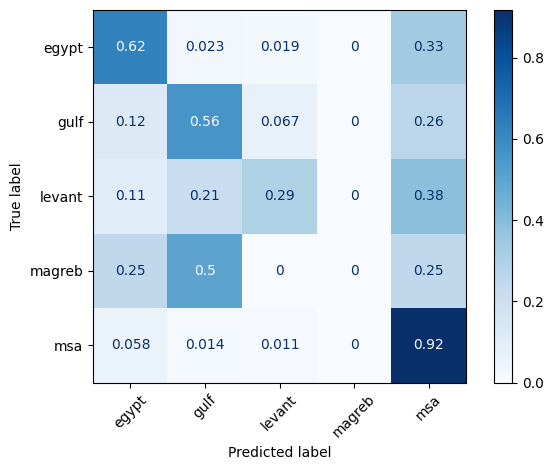

In [6]:
y_true, y_pred = show_errors(trainer_b1, tok_data_b1, splits["test"], id2label, n=10)
print(classification_report(y_true, y_pred, target_names=label_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred, normalize="true")
ConfusionMatrixDisplay(cm, display_labels=label_names).plot(cmap="Blues", xticks_rotation=45)
plt.tight_layout(); plt.savefig("confusion_matrix_B1.png", dpi=150); plt.show()

## **Improvement: Class weights**



In [7]:
y = np.array(splits["train"]["label"])
w = compute_class_weight("balanced", classes=np.arange(len(label_names)), y=y)
class_weights = torch.tensor(w, dtype=torch.float)
print(dict(zip(label_names, w.round(2))))

trainer_b2, tok_b2, tok_data_b2, m_b2 = train_model(
    "UBC-NLP/MARBERT", "B2_marbert_weighted", splits, id2label, lr=2e-5, epochs=5,
    batch_size=32, max_length=128, class_weights=class_weights)
results.append(result_row("B2 MARBERT + class weights", m_b2))
pd.DataFrame(results)

{'egypt': np.float64(0.88), 'gulf': np.float64(4.53), 'levant': np.float64(3.83), 'magreb': np.float64(68.89), 'msa': np.float64(0.3)}


Map:   0%|          | 0/7233 [00:00<?, ? examples/s]

Map:   0%|          | 0/804 [00:00<?, ? examples/s]

Map:   0%|          | 0/2094 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: UBC-NLP/MARBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider

... (4 outputs left out)

Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
No log,0.981833,3,0.796020,0.690338,0.650687,0.637514,0.804416


[transformers] early stopping required metric_for_best_model, but did not find eval_f1_macro so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
No log,1.128160,3,0.766953,0.532683,0.564679,0.532653,0.773288


,run,val_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_weighted
0,B1 MARBERT baseline,0.5222,0.7975,0.5211,0.4788,0.4924,0.7882
1,B2 MARBERT + class weights,0.6375,0.7670,0.5327,0.5647,0.5327,0.7733


## **Improvement: Dialect-adapted model**


In [8]:
trainer_b3, tok_b3, tok_data_b3, m_b3 = train_model(
    "CAMeL-Lab/bert-base-arabic-camelbert-da", "B3_camelbert_da", splits, id2label, lr=3e-5, epochs=5,
    batch_size=32, max_length=128, class_weights=class_weights)
results.append(result_row("B3 CAMeLBERT-DA + class weights", m_b3))

config.json:   0%|          | 0.00/468 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/7233 [00:00<?, ? examples/s]

Map:   0%|          | 0/804 [00:00<?, ? examples/s]

... (12 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
0.841888,1.005227,5,0.776119,0.540987,0.725423,0.594881,0.786410


[transformers] early stopping required metric_for_best_model, but did not find eval_f1_macro so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
0.841888,1.355504,5,0.752149,0.481787,0.555476,0.509529,0.761445


In [9]:
res_b = pd.DataFrame(results)
res_b.to_csv("results_project_B.csv", index=False)
res_b

,run,val_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_weighted
0,B1 MARBERT baseline,0.5222,0.7975,0.5211,0.4788,0.4924,0.7882
1,B2 MARBERT + class weights,0.6375,0.7670,0.5327,0.5647,0.5327,0.7733
2,B3 CAMeLBERT-DA + class weights,0.5949,0.7521,0.4818,0.5555,0.5095,0.7614


In [10]:
best_trainer, best_tok = trainer_b2, tok_b2     # change to the run you picked
best_trainer.save_model("saved_dialect_identifier")
best_tok.save_pretrained("saved_dialect_identifier")

clf = pipeline("text-classification", model="saved_dialect_identifier", top_k=3,
               device=0 if torch.cuda.is_available() else -1)
new_texts = ["إنت بتعمل إيه دلوقتي؟ تعالى نشرب قهوة",
             "شلونك وش تسوي الحين؟",
             "كيفك شو عم تعمل هلق؟",
             "شنو كتدير دابا؟",
             "ماذا تفعل الآن؟ لقد انتظرتك طويلا"]
for t in new_texts:
    res = clf(t)
    res = res[0] if isinstance(res[0], list) else res
    print(t, "->", [(r["label"], round(r["score"], 2)) for r in res])

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

إنت بتعمل إيه دلوقتي؟ تعالى نشرب قهوة -> [('egypt', 0.8), ('msa', 0.06), ('levant', 0.06)]
شلونك وش تسوي الحين؟ -> [('gulf', 0.61), ('levant', 0.21), ('egypt', 0.08)]
كيفك شو عم تعمل هلق؟ -> [('levant', 0.59), ('gulf', 0.14), ('egypt', 0.09)]
شنو كتدير دابا؟ -> [('levant', 0.3), ('gulf', 0.24), ('msa', 0.19)]
ماذا تفعل الآن؟ لقد انتظرتك طويلا -> [('msa', 0.44), ('egypt', 0.34), ('levant', 0.11)]


In [11]:
import gradio as gr
def predict(text):
    res = clf(text)
    res = res[0] if isinstance(res[0], list) else res
    return {r["label"]: float(r["score"]) for r in res}

gr.Interface(fn=predict,
             inputs=gr.Textbox(lines=3, label="Arabic text", rtl=True),
             outputs=gr.Label(num_top_classes=3, label="Predicted dialect"),
             title="Arabic Dialect Identifier",
             examples=new_texts).launch(share=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://8c67bb61df63997bfa.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [12]:
!zip -r /kaggle/working/saved_dialect_identifier.zip saved_dialect_identifier

from IPython.display import FileLink, display
display(FileLink('/kaggle/working/saved_dialect_identifier.zip'))

  adding: saved_dialect_identifier/ (stored 0%)
  adding: saved_dialect_identifier/training_args.bin (deflated 53%)
  adding: saved_dialect_identifier/tokenizer.json (deflated 72%)
  adding: saved_dialect_identifier/model.safetensors (deflated 7%)
  adding: saved_dialect_identifier/config.json (deflated 56%)
  adding: saved_dialect_identifier/tokenizer_config.json (deflated 46%)


/kaggle/working/saved_dialect_identifier.zip